# Auswertung Phase 2 und Begleitfragebogen

In [ ]:
# %pip install pandas openpyxl jupyter

In [ ]:
from pathlib import Path
import re

import pandas as pd

SOURCE_DIR = Path("data")
OUTPUT_DIR = Path("outputs")
FIGURE_DIR = Path("figures")
OUTPUT_DIR.mkdir(exist_ok=True)
FIGURE_DIR.mkdir(exist_ok=True)


SOURCE_FILE = "User_Tests_Phase2_und_Begleitfragebogen.xlsx"
source_path = SOURCE_DIR / SOURCE_FILE

In [4]:
def clean_column_name(column):
    column = str(column).strip().lower()
    column = column.replace("ä", "ae").replace("ö", "oe").replace("ü", "ue").replace("ß", "ss")
    column = re.sub(r"[^a-z0-9]+", "_", column)
    column = re.sub(r"_+", "_", column).strip("_")
    return column or "unnamed"


if not source_path.exists():
    raise FileNotFoundError(f"Datei nicht gefunden: {source_path}. Bitte Google Sheet als CSV/XLSX nach data/ exportieren.")

if source_path.suffix.lower() == ".csv":
    raw_df = pd.read_csv(source_path)
elif source_path.suffix.lower() in [".xlsx", ".xls"]:
    try:
        raw_df = pd.read_excel(source_path, engine="openpyxl")
    except ImportError as exc:
        raise ImportError("Zum Lesen von XLSX-Dateien fehlt openpyxl. Fuehre oben aus: %pip install openpyxl") from exc
else:
    raise ValueError(f"Nicht unterstuetztes Format: {source_path.suffix}")

df = raw_df.copy()
df.columns = [clean_column_name(column) for column in df.columns]

print("Zeilen:", len(df))
print("Spalten:", len(df.columns))
display(df.head())

Zeilen: 13
Spalten: 15


,tester_id,15,14,13,12,11,10,9,8,7,6,5,4,2,1
0,Datum & Uhrzeit,28.07 - 14:16,28.07 - 13:00,28.07.2026 - 10:45,2026-07-27 17:15:00,27.07 - 15:35,2026-07-27 15:05:00,27.07 - 14:10,27.07.2026 - 13:20,24.7 - 14:45,24.07 - 13:45,24.07 - 11:50,2026-07-24 11:00:00,2026-07-22 16:00:00,2026-07-22 15:20:00
1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,Gewählte Einstellung,8,8,7,9,6,1,7,1,8,7,6,7,1,8
4,Warum?,"licht und schattenverhältnis ist gut, 1 schatt...","Licht kommt glaubhaft vom fenster, schatten lä...","helligkeit passt zur tageszeit, schatten eindi...","nicht zu hell, nicht zu harte schatten","erleichtert die bedienung, aber schöneres lich...","Schatten sind sehr klar, 1 fügt sich besser ei...","Gute Helligkeit, schöner schatten, realistisch...","wegen helligkeit , wegen schatten alles andere...",acht hat tolle schatten die man auch sieht wen...,Lichtstimmung passt zum raum - 8 und 9 sind au...,"helligkeit, kontrastreicher schatten, geradlie...","Schöner Schatten, nicht zu hart nicht zu weich...","Der stärkste Schatten wird abgenommen, auch we...","Coole helligkeit, schatten nicht zu hart, nich..."


In [7]:
clean_output_path = OUTPUT_DIR / "User_Tests_Phase2_und_Begleitfragebogen.csv"
df.to_csv(clean_output_path, index=False)
print(f"Bereinigte Datei geschrieben: {clean_output_path}")

Bereinigte Datei geschrieben: outputs/User_Tests_Phase2_und_Begleitfragebogen.csv


## Gewählte Einstellung: Häufigkeit

Die Google-Sheet-Datei ist transponiert: Personen stehen in den Spalten, Kategorien in den Zeilen. Dieser Block dreht die Tabelle in ein sauberes Format und zählt, welche Einstellung wie oft gewählt wurde.

In [8]:
# Sheet-Struktur drehen: erste Spalte enthaelt die Feldnamen, alle weiteren Spalten sind Personen.
wide = raw_df.copy()
wide = wide.rename(columns={wide.columns[0]: "field"})
long_df = wide.set_index("field").T.reset_index(drop=True)
long_df.columns = [clean_column_name(column) for column in long_df.columns]

# Wichtige Spalten etwas lesbarer benennen, falls sie vorhanden sind.
rename_candidates = {
    "tester_id": "tester_id",
    "gewaehlte_einstellung": "selected_setting",
}
long_df = long_df.rename(columns={old: new for old, new in rename_candidates.items() if old in long_df.columns})

long_df["selected_setting"] = pd.to_numeric(long_df["selected_setting"], errors="coerce").astype("Int64")
SETTING_LABELS = {setting: f"L{setting:02d}" for setting in range(1, 10)}
long_df.to_csv(OUTPUT_DIR / "level6_participants_clean.csv", index=False)

print("Personen:", len(long_df))
display(long_df.head())

Personen: 14


,datum_uhrzeit,nan,nan,selected_setting,warum,allgemeine_kommentare,nan,nan,alter,geschlecht,beruf,computerspiele,ar_vorerfahrung
0,28.07 - 14:16,NaN,NaN,8,"licht und schattenverhältnis ist gut, 1 schatt...","09 wärmer mehrere schatten tanzen ganz nett, 6...",NaN,NaN,26-34,weiblich,Architektur,Nie,Nie
1,28.07 - 13:00,NaN,NaN,8,"Licht kommt glaubhaft vom fenster, schatten lä...",1 ist entsättigt und passt nicht zu der realen...,NaN,NaN,26-34,männlich,Architektur,Selten,Bereits ausprobiert
2,28.07.2026 - 10:45,NaN,NaN,7,"helligkeit passt zur tageszeit, schatten eindi...","jedes mal sieht es anders aus, was mit einem s...",NaN,NaN,26-34,männlich,Media Design,regelmäßig,Bereits ausprobiert
3,2026-07-27 17:15:00,NaN,NaN,9,"nicht zu hell, nicht zu harte schatten",unterschiedliche licht situationen nicht aufge...,NaN,NaN,20-25,weiblich,Architektur,nie,Bereits ausprobiert
4,27.07 - 15:35,NaN,NaN,6,"erleichtert die bedienung, aber schöneres lich...","1 ist zu flach und zu dunkel -licht hart, 2 do...",NaN,NaN,26-34,männlich,Media Design,Sehr häufig,Bereits ausprobiert


In [9]:
setting_counts = (
    long_df["selected_setting"]
    .value_counts(dropna=False)
    .rename_axis("selected_setting")
    .reset_index(name="count")
    .sort_values("selected_setting")
)
setting_counts["percent"] = setting_counts["count"] / setting_counts["count"].sum() * 100
setting_counts.to_csv(OUTPUT_DIR / "level6_selected_setting_counts.csv", index=False)
setting_counts

,selected_setting,count,percent
2,1,3,21.428571
3,6,2,14.285714
1,7,4,28.571429
0,8,4,28.571429
4,9,1,7.142857


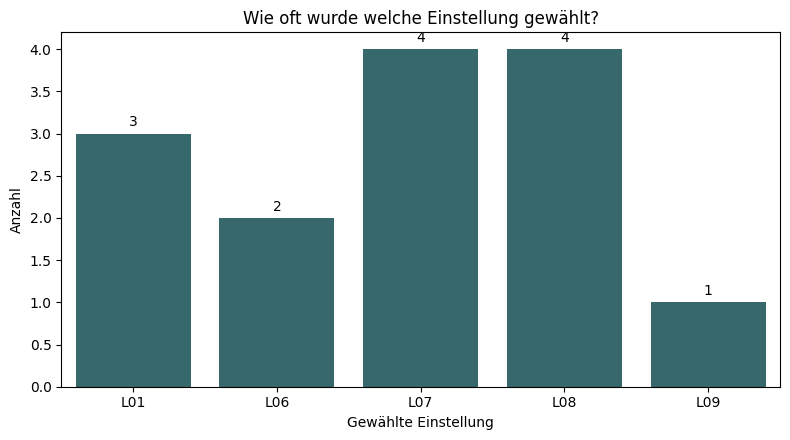

In [10]:
import matplotlib.pyplot as plt
import seaborn as sns

plot_counts = setting_counts.copy()
plot_counts["selected_setting_label"] = plot_counts["selected_setting"].map(SETTING_LABELS)

plt.figure(figsize=(8, 4.5))
ax = sns.barplot(
    data=plot_counts,
    x="selected_setting_label",
    y="count",
    color="#2f6f73",
)
for container in ax.containers:
    ax.bar_label(container, fmt="%d", padding=3)

plt.xlabel("Gewählte Einstellung")
plt.ylabel("Anzahl")
plt.title("Wie oft wurde welche Einstellung gewählt?")
plt.tight_layout()
plt.savefig("figures/level6_gewaehlte_einstellung_counts.png", dpi=300)
plt.show()

## Licht- und Schattenkategorien

Diese beiden Diagramme gruppieren die gewaehlten Einstellungen in inhaltliche Kategorien. Innerhalb jedes Balkens bleiben die konkreten Einstellungen als gestapelte farbige Segmente sichtbar.

Licht: Environment Lighting (Apple), Single Light, Multi-Light.

Schatten: No Shadow, Grounding Shadow (Apple), Multi-Shadow, Single Shadow.

In [11]:
LIGHT_SETTING_COLORS = {
    1: "#8fb9a8",
    2: "#5f947d",
    3: "#d6a04d",
    4: "#9bb8d3",
    5: "#739cc2",
    6: "#527fae",
    7: "#38679b",
    8: "#24517f",
    9: "#163a5f",
}

SHADOW_SETTING_COLORS = {
    1: "#7fb069",
    2: "#d8b365",
    3: "#7d6fb2",
    4: "#a9c6d9",
    5: "#7faac5",
    6: "#4c8c5f",
    7: "#69509c",
    8: "#50377f",
    9: "#5789aa",
}


def build_grouped_setting_counts(setting_series, category_map):
    rows = []
    settings = sorted(category_map)
    for setting in settings:
        rows.append({
            "setting": setting,
            "category": category_map[setting],
            "count": int((setting_series == setting).sum()),
        })
    return pd.DataFrame(rows)

def plot_grouped_stacked_settings(counts_df, category_order, title, filename, setting_colors):
    pivot = (
        counts_df.pivot_table(index="category", columns="setting", values="count", aggfunc="sum", fill_value=0)
        .reindex(category_order)
        .fillna(0)
    )
    settings = list(pivot.columns)
    # Drei Licht-Kategorien und vier Schatten-Kategorien erhalten dieselbe sichtbare Balkenbreite.
    bar_width = 0.52 * len(category_order) / 4

    ax = pivot.plot(
        kind="bar",
        stacked=True,
        figsize=(8, 4.5),
        width=bar_width,
        color=[setting_colors.get(int(setting), "#999999") for setting in settings],
        edgecolor="white",
        linewidth=0.8,
    )

    totals = pivot.sum(axis=1)
    for x_position, total in enumerate(totals):
        ax.text(x_position, total + 0.08, str(int(total)), ha="center", va="bottom")

    ax.set_xlabel("")
    ax.set_ylabel("Anzahl gewählter Einstellungen")
    ax.set_title(title)
    ax.set_ylim(0, max(totals.max() + 1, 1))
    ax.legend(
        labels=[SETTING_LABELS.get(int(setting), str(setting)) for setting in settings],
        title="Einstellung",
        bbox_to_anchor=(1.02, 1),
        loc="upper left",
    )
    plt.xticks(rotation=0)
    plt.tight_layout()
    plt.savefig(FIGURE_DIR / filename, dpi=300)
    plt.show()


,setting,category,count
0,1,Environment Lighting,3
1,2,Environment Lighting,0
2,3,Single Light,0
3,4,Multi-Light,0
4,5,Multi-Light,0
5,6,Multi-Light,2
6,7,Multi-Light,4
7,8,Multi-Light,4
8,9,Multi-Light,1


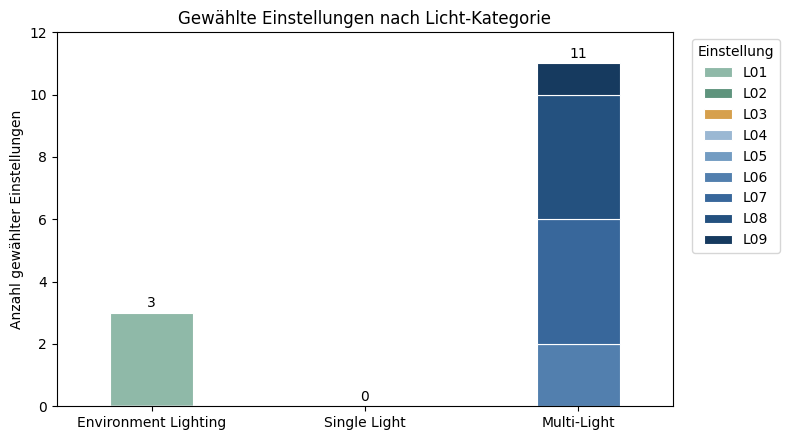

In [12]:
light_category_map = {
    1: "Environment Lighting",
    2: "Environment Lighting",
    3: "Single Light",
    4: "Multi-Light",
    5: "Multi-Light",
    6: "Multi-Light",
    7: "Multi-Light",
    8: "Multi-Light",
    9: "Multi-Light",
}
light_category_order = ["Environment Lighting", "Single Light", "Multi-Light"]

light_counts = build_grouped_setting_counts(long_df["selected_setting"], light_category_map)
light_counts.to_csv(OUTPUT_DIR / "level6_light_category_setting_counts.csv", index=False)
display(light_counts)

plot_grouped_stacked_settings(
    light_counts,
    category_order=light_category_order,
    title="Gewählte Einstellungen nach Licht-Kategorie",
    filename="level6_licht_kategorien_stacked.png",
    setting_colors=LIGHT_SETTING_COLORS,
)

,setting,category,count
0,1,Grounding Shadow,3
1,2,No Shadow,0
2,3,Single Shadow,0
3,4,Multi-Shadow,0
4,5,Multi-Shadow,0
5,6,Grounding Shadow,2
6,7,Single Shadow,4
7,8,Single Shadow,4
8,9,Multi-Shadow,1


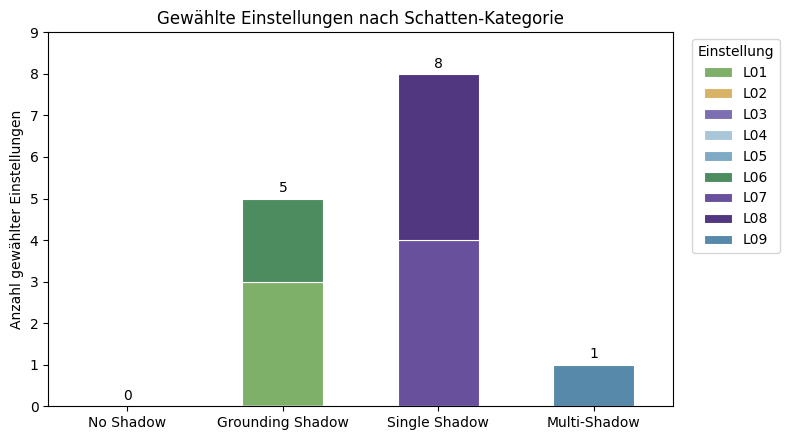

In [13]:
shadow_category_map = {
    2: "No Shadow",
    1: "Grounding Shadow",
    6: "Grounding Shadow",
    4: "Multi-Shadow",
    5: "Multi-Shadow",
    9: "Multi-Shadow",
    3: "Single Shadow",
    7: "Single Shadow",
    8: "Single Shadow",
}
shadow_category_order = ["No Shadow", "Grounding Shadow", "Single Shadow", "Multi-Shadow"]

shadow_counts = build_grouped_setting_counts(long_df["selected_setting"], shadow_category_map)
shadow_counts.to_csv(OUTPUT_DIR / "level6_shadow_category_setting_counts.csv", index=False)
display(shadow_counts)

plot_grouped_stacked_settings(
    shadow_counts,
    category_order=shadow_category_order,
    title="Gewählte Einstellungen nach Schatten-Kategorie",
    filename="level6_schatten_kategorien_stacked.png",
    setting_colors=SHADOW_SETTING_COLORS,
)

## Gewaehlte Einstellung nach Beruf und Alter

Diese Diagramme zeigen, welche Einstellungen je Berufskategorie und Altersgruppe gewaehlt wurden. Die Balken sind nach Einstellung gestapelt.

In [15]:
if "SETTING_COLORS_BY_ID" not in globals():
    SETTING_COLORS_BY_ID = {
        1: "#4c78a8",
        2: "#72b7b2",
        3: "#f2cf5b",
        4: "#9bb8d3",
        5: "#7faac5",
        6: "#4f8db5",
        7: "#7d6fb2",
        8: "#5d4a9b",
        9: "#9d755d",
    }

demographic_df = long_df.copy()
demographic_df["selected_setting"] = pd.to_numeric(demographic_df["selected_setting"], errors="coerce").astype("Int64")
demographic_df["beruf"] = demographic_df["beruf"].astype(str).str.strip()
demographic_df["beruf"] = demographic_df["beruf"].replace({"Architekur": "Architektur"})
demographic_df["alter"] = demographic_df["alter"].astype(str).str.strip()

display(demographic_df[["alter", "beruf", "selected_setting"]])

,alter,beruf,selected_setting
0,26-34,Architektur,8
1,26-34,Architektur,8
2,26-34,Media Design,7
3,20-25,Architektur,9
4,26-34,Media Design,6
5,20-25,Architektur,1
6,20-25,Media Design,7
7,20-25,Architektur,1
8,26-34,Media Design,8
9,35-50,Media Design,7


In [16]:
def plot_setting_by_group(data, group_col, group_order, title, filename):
    counts = pd.crosstab(data[group_col], data["selected_setting"])
    counts = counts.reindex(index=group_order)
    counts = counts.reindex(columns=sorted(data["selected_setting"].dropna().unique()), fill_value=0)
    counts = counts.fillna(0)

    ax = counts.plot(
        kind="bar",
        stacked=True,
        figsize=(8, 4.5),
        width=0.58,
        color=[SETTING_COLORS_BY_ID.get(int(setting), "#999999") for setting in counts.columns],
        edgecolor="white",
        linewidth=0.8,
    )

    totals = counts.sum(axis=1)
    for x_position, total in enumerate(totals):
        ax.text(x_position, total + 0.08, str(int(total)), ha="center", va="bottom")

    ax.set_xlabel("")
    ax.set_ylabel("Anzahl")
    ax.set_title(title)
    ax.set_ylim(0, max(totals.max() + 1, 1))
    ax.legend(
        labels=[SETTING_LABELS.get(int(setting), str(setting)) for setting in counts.columns],
        title="Einstellung",
        bbox_to_anchor=(1.02, 1),
        loc="upper left",
    )
    plt.xticks(rotation=0)
    plt.tight_layout()
    plt.savefig(FIGURE_DIR / filename, dpi=300)
    plt.show()

    return counts


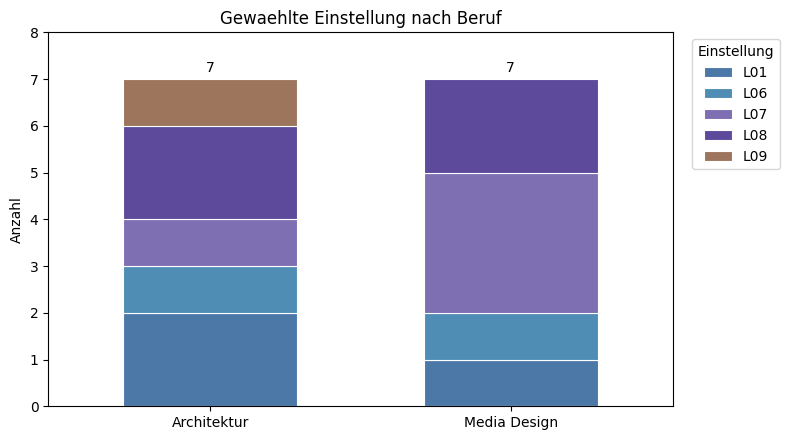

selected_setting,1,6,7,8,9
beruf,,,,,
Architektur,2,1,1,2,1
Media Design,1,1,3,2,0


In [226]:
beruf_order = ["Architektur", "Media Design"]
settings_by_beruf = plot_setting_by_group(
    demographic_df,
    group_col="beruf",
    group_order=beruf_order,
    title="Gewaehlte Einstellung nach Beruf",
    filename="level6_gewaehlte_einstellung_nach_beruf.png",
)
settings_by_beruf.to_csv(OUTPUT_DIR / "level6_selected_setting_by_beruf.csv")
settings_by_beruf

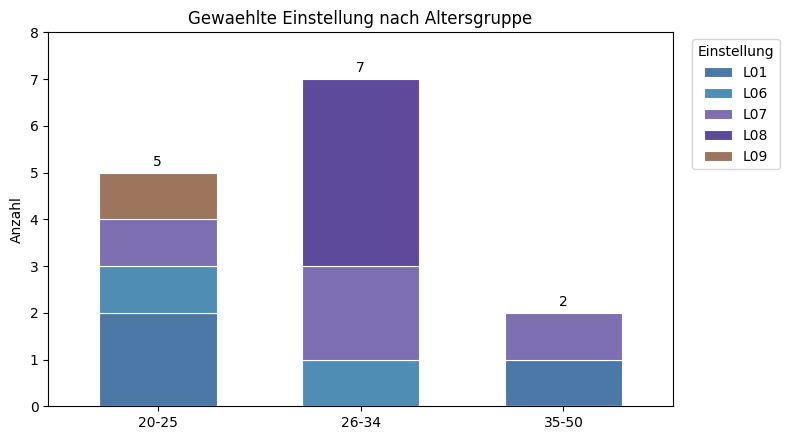

selected_setting,1,6,7,8,9
alter,,,,,
20-25,2,1,1,0,1
26-34,0,1,2,4,0
35-50,1,0,1,0,0


In [17]:
age_order = sorted(demographic_df["alter"].dropna().unique())
settings_by_age = plot_setting_by_group(
    demographic_df,
    group_col="alter",
    group_order=age_order,
    title="Gewaehlte Einstellung nach Altersgruppe",
    filename="level6_gewaehlte_einstellung_nach_altersgruppe.png",
)
settings_by_age.to_csv(OUTPUT_DIR / "level6_selected_setting_by_age.csv")
settings_by_age

## Gewählte Einstellung nach Geschlecht und Computerspielhäufigkeit

Diese Diagramme zeigen, welche Einstellungen je Geschlecht und Computerspielhäufigkeit gewählt wurden.

In [19]:
demographic_df["geschlecht"] = demographic_df["geschlecht"].astype(str).str.strip().str.capitalize()
demographic_df["computerspiele"] = (
    demographic_df["computerspiele"]
    .astype(str)
    .str.strip()
    .str.lower()
)
demographic_df["computerspiele"] = demographic_df["computerspiele"].replace({
    "nie": "Nie",
    "selten": "Selten",
    "manchmal": "Manchmal",
    "regelmäßig": "Regelmäßig",
    "regelmaessig": "Regelmäßig",
    "häufig": "Häufig",
    "haeufig": "Häufig",
    "sehr häufig": "Sehr häufig",
    "sehr haeufig": "Sehr häufig",
})
demographic_df["ar_vorerfahrung"] = (
    demographic_df["ar_vorerfahrung"].astype(str).str.strip().str.lower().replace({
        "nie": "Nie",
        "bereits ausprobiert": "Bereits ausprobiert",
        "regelmäßig": "Regelmäßig",
        "regelmaessig": "Regelmäßig",
    })
)

display(demographic_df[[ "geschlecht", "computerspiele", "selected_setting"]])

,geschlecht,computerspiele,selected_setting
0,Weiblich,Nie,8
1,Männlich,Selten,8
2,Männlich,Regelmäßig,7
3,Weiblich,Nie,9
4,Männlich,Sehr häufig,6
5,Weiblich,Selten,1
6,Weiblich,Selten,7
7,Weiblich,Selten,1
8,Männlich,Regelmäßig,8
9,Männlich,Manchmal,7


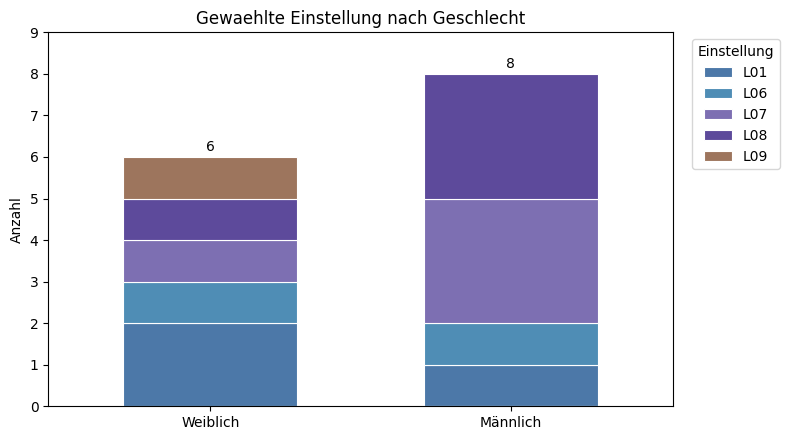

selected_setting,1,6,7,8,9
geschlecht,,,,,
Weiblich,2,1,1,1,1
Männlich,1,1,3,3,0


In [20]:
gender_order = [group for group in ["Weiblich", "Männlich", "Divers"] if group in set(demographic_df["geschlecht"])]
settings_by_gender = plot_setting_by_group(
    demographic_df,
    group_col="geschlecht",
    group_order=gender_order,
    title="Gewaehlte Einstellung nach Geschlecht",
    filename="level6_gewaehlte_einstellung_nach_geschlecht.png",
)
settings_by_gender.to_csv(OUTPUT_DIR / "level6_selected_setting_by_gender.csv")
settings_by_gender

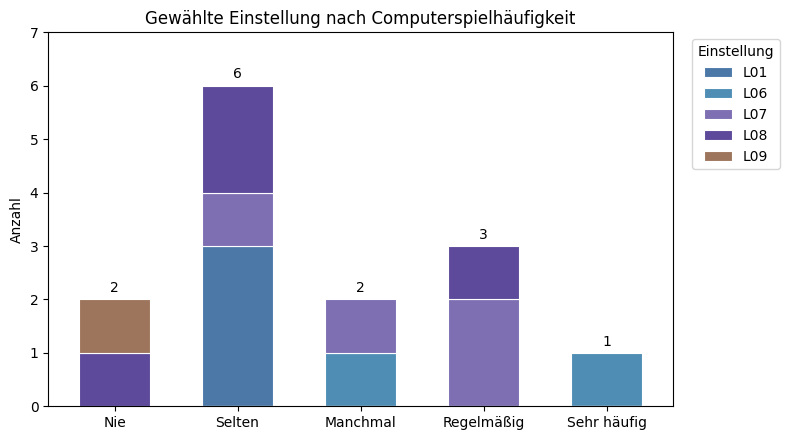

selected_setting,1,6,7,8,9
computerspiele,,,,,
Nie,0,0,0,1,1
Selten,3,0,1,2,0
Manchmal,0,1,1,0,0
Regelmäßig,0,0,2,1,0
Sehr häufig,0,1,0,0,0


In [21]:
game_order = [group for group in ["Nie", "Selten", "Manchmal", "Regelmäßig", "Sehr häufig"] if group in set(demographic_df["computerspiele"])]
remaining_game_groups = [group for group in sorted(demographic_df["computerspiele"].dropna().unique()) if group not in game_order]
game_order = game_order + remaining_game_groups

settings_by_games = plot_setting_by_group(
    demographic_df,
    group_col="computerspiele",
    group_order=game_order,
    title="Gewählte Einstellung nach Computerspielhäufigkeit",
    filename="level6_gewaehlte_einstellung_nach_computerspiele.png",
)
settings_by_games.to_csv(OUTPUT_DIR / "level6_selected_setting_by_games.csv")
settings_by_games

## Demografische Übersicht

Die Verteilung der Teilnehmenden nach Geschlecht, Altersgruppe, Beruf, AR/VR-Erfahrung und Computerspielhäufigkeit.

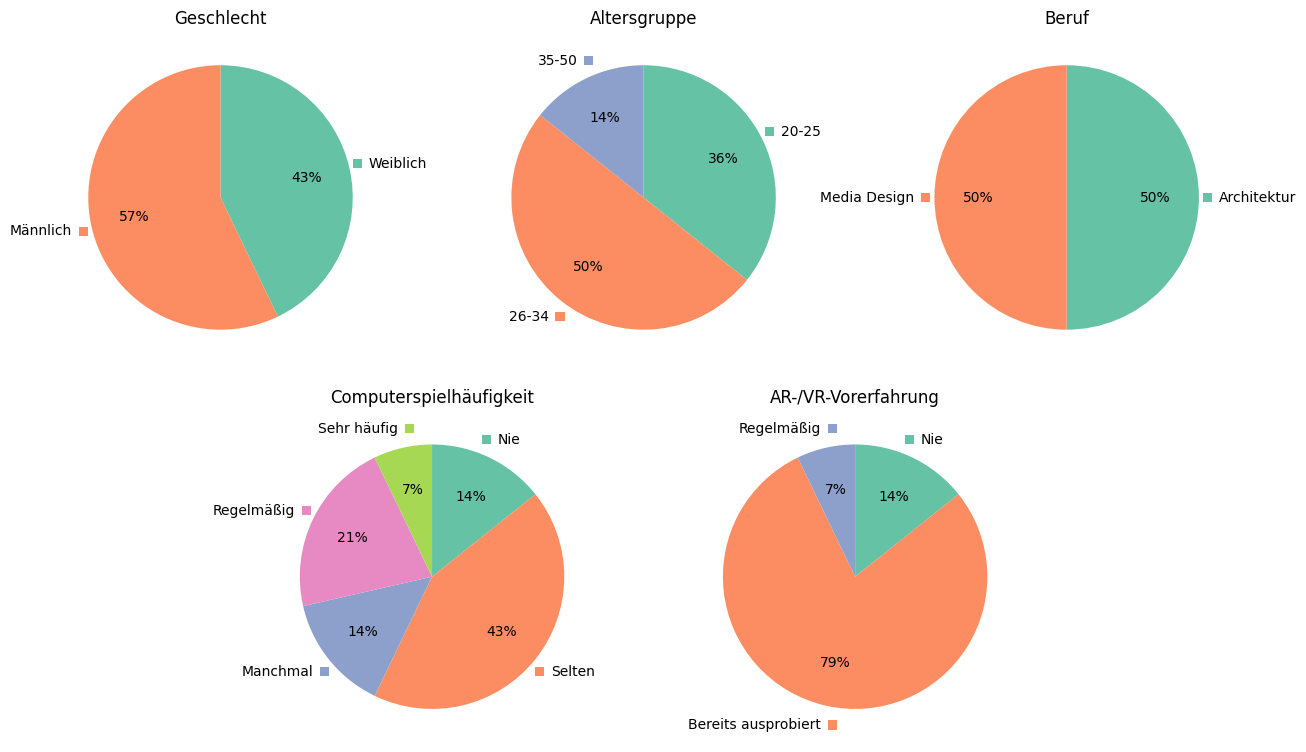

,category,value,count,percent
0,Geschlecht,Weiblich,6,42.857143
1,Geschlecht,Männlich,8,57.142857
2,Altersgruppe,20-25,5,35.714286
3,Altersgruppe,26-34,7,50.000000
4,Altersgruppe,35-50,2,14.285714
5,Beruf,Architektur,7,50.000000
6,Beruf,Media Design,7,50.000000
7,Computerspielhäufigkeit,Nie,2,14.285714
8,Computerspielhäufigkeit,Selten,6,42.857143
9,Computerspielhäufigkeit,Manchmal,2,14.285714


In [23]:
demographic_charts = [
    ("geschlecht", "Geschlecht", ["Weiblich", "Männlich", "Divers"]),
    ("alter", "Altersgruppe", ["20-25", "26-34", "35-50"]),
    ("beruf", "Beruf", ["Architektur", "Media Design"]),
    ("computerspiele", "Computerspielhäufigkeit", game_order),
    ("ar_vorerfahrung", "AR-/VR-Vorerfahrung", ["Nie", "Bereits ausprobiert", "Regelmäßig"]),
]

summary_rows = []
fig = plt.figure(figsize=(13, 8.5))
grid = fig.add_gridspec(2, 6)
axes = [
    fig.add_subplot(grid[0, 0:2]),
    fig.add_subplot(grid[0, 2:4]),
    fig.add_subplot(grid[0, 4:6]),
    fig.add_subplot(grid[1, 1:3]),
    fig.add_subplot(grid[1, 3:5]),
]

for ax, (column, title, preferred_order) in zip(axes, demographic_charts):
    counts = demographic_df[column].dropna().value_counts()
    order = [value for value in preferred_order if value in counts.index]
    order += [value for value in counts.index if value not in order]
    counts = counts.reindex(order)

    colors = sns.color_palette("Set2", n_colors=len(counts))
    wedges, label_texts, _ = ax.pie(
        counts.values,
        colors=colors,
        startangle=90,
        counterclock=False,
        labels=[str(label) for label in counts.index],
        labeldistance=1.15,
        autopct=lambda percent: f"{percent:.0f}%",
        pctdistance=0.67,
        textprops={"fontsize": 10},
    )
    for wedge, label_text in zip(wedges, label_texts):
        label_x, label_y = label_text.get_position()
        square_x = label_x - 0.12 if label_x > 0 else label_x + 0.05
        ax.add_patch(
            plt.Rectangle(
                (square_x, label_y - 0.035),
                0.07,
                0.07,
                facecolor=wedge.get_facecolor(),
                edgecolor="none",
                clip_on=False,
            )
        )
    ax.set_title(title)

    summary_rows.extend(
        {"category": title, "value": label, "count": int(count), "percent": count / counts.sum() * 100}
        for label, count in counts.items()
    )

plt.tight_layout(rect=(0, 0.04, 1, 0.95))
plt.savefig(FIGURE_DIR / "level6_demografische_uebersicht.png", dpi=300, bbox_inches="tight")
plt.show()

demographic_summary = pd.DataFrame(summary_rows)
demographic_summary.to_csv(OUTPUT_DIR / "level6_demografische_uebersicht.csv", index=False)
demographic_summary